# <font color='#2E86C1' size=6>**Preprocessing recipe and model choice**</font>

**Workflow:** [01 Data cleaning](01_data_cleaning.ipynb) → [02 Customer table](02_customer_table.ipynb) → [03 Missing values](03_missing_values.ipynb) → [04 Outliers](04_outlier_detection.ipynb) → **05 Pipeline and models** → [06 Feature engineering and selection](06_feature_engineering_selection.ipynb)

The leak-safe preprocessing recipe of each task (`build_preprocessor()`), the encoder × scaler pair and the model, chosen on the development set with the temporal folds and the decision rule of notebook 01 (section 7). The imputers inside the recipe come from notebook 03, and the features it uses from notebook 06. The notebook imports the pipeline's own functions, so it always runs the same code as `python main.py`.

## Table of Contents <a class="anchor" id="toc"></a>
- [0. Setup](#setup)
- [1. `build_preprocessor()`](#recipe)
- [2. Choosing the encoder × scaler pair](#encoder-scaler)
- [3. Recipe + model = one Pipeline](#pipeline)
- [4. Model scores with the final recipe](#scores)
- [5. From this notebook to the pipeline](#to-pipeline)

# <font color='#2E86C1' size=6>**0. Setup**</font> <a class="anchor" id="setup"></a>

[Back to TOC](#toc)

In [1]:
import os
import sys
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from src.cleaning import drop_training_rows, fill_from_customer_history, prepare_table
from src.data import load_data
from src.evaluate import compare_encoders_scalers, cross_validate_pipeline, paired_comparison, select_scoring, temporal_folds
from src.pipeline import build_pipeline, predict_new_records, prepare_task_data
from src.preprocessing import build_preprocessor, check_feature_lists, split_dev_test, task_preprocessing_config
from src.tasks import TASKS
import classification.preprocessing as classification_prep
import regression.preprocessing as regression_prep
import classification.model as classification_model
import regression.model as regression_model

# every rule and choice (column lists, placeholder value, seeds, ...) comes from config.yaml
with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
data_cfg, diag_cfg, prep_cfg = config["data"], config["diagnostics"], config["preprocessing"]
date_col = data_cfg["date_column"]

# each task's metrics (config.yaml -> <task>.metrics) as sklearn scoring strings
SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}
TASK_MODELS = {"classification": classification_model, "regression": regression_model}


In [2]:
# the purchase files after the stateless rules and the customer-history fill (notebook 01, sections 5-6)
tokens = diag_cfg["placeholder_tokens"]
train_raw = load_data(data_cfg["train_path"], tokens)
test_raw = load_data(data_cfg["test_path"], tokens)
clientes_raw = load_data(data_cfg["clientes_path"], tokens)
train_rules, _ = prepare_table(train_raw, config, clientes_raw)
test_rules, _ = prepare_table(test_raw, config, clientes_raw)
train_rules, _ = drop_training_rows(train_rules, diag_cfg, data_cfg["id_column"], config["customers"])
history = pd.concat([train_rules, test_rules], ignore_index=True)
train_rules, _ = fill_from_customer_history(train_rules, history, diag_cfg, data_cfg["id_column"])
test_rules, _ = fill_from_customer_history(test_rules, history, diag_cfg, data_cfg["id_column"])

# each task's development set, locked test set and temporal folds (notebook 01, sections 6-7); test.csv
splits, task_folds = {}, {}
for task, task_prep in {"classification": classification_prep, "regression": regression_prep}.items():
    X, y, extras = task_prep.prepare_features(task_prep.select_training_rows(train_rules, config), config)
    splits[task] = split_dev_test(X, y, extras, config["test_set"], date_col)
    task_folds[task] = temporal_folds(splits[task][4][date_col], config["cv"]["n_splits"], config["cv"]["gap_days"])
    print(f"{task:>14}: development {len(splits[task][0])} rows, locked test {len(splits[task][1])} rows, "
          f"{len(task_folds[task])} temporal folds")
X_kaggle, y_kaggle, extras_kaggle = classification_prep.prepare_features(test_rules, config)
print(f"{'test.csv':>14}: {len(X_kaggle)} rows")


classification: development 5024 rows, locked test 1286 rows, 5 temporal folds
    regression: development 2659 rows, locked test 685 rows, 5 temporal folds
      test.csv: 986 rows


# <font color='#2E86C1' size=6>**1. `build_preprocessor()`**</font> <a class="anchor" id="recipe"></a>

One `ColumnTransformer`, built entirely from `config.yaml` → `preprocessing`:

| Group | Steps |
|---|---|
| numeric features | median imputer with row limits (`RowBoundedImputer`: the median is learned without the structural zeros of first purchases; the regression estimates `spend_365d` as 365-day purchase count × mean purchase value; an imputed value is kept within its row's limits) → scaler (standard for classification, min-max for regression) |
| categorical features | most-frequent imputer → target encoder (`handle_unknown`: unseen categories get the overall target mean) |
| indicators | `MissingIndicator` on `spend_365d` (`mnar_indicator_sources`). It sees the **original** column, before the numeric imputer fills it, and is part of the pipeline |
| flags | `is_first_purchase`, `has_gap_history` passed through |

The shared default in `config.yaml` → `preprocessing` was a first choice with a reason: target encoding gives one column per feature (`transport_method` has 80 levels), and robust scaling uses median/IQR, so the skewed amounts with extreme values don't set the scale. Section 2 compares every encoder × scaler pair, and each task stores its winner in `config.yaml` → `<task>.preprocessing`; `task_preprocessing_config()` merges the two.

Before building it, `check_feature_lists()` checks the feature lists in `config.yaml`: every listed feature must exist in the data, no feature may be in two groups (numeric / categorical / flags) or listed twice, and every indicator source must be a feature. `build_preprocessor()` runs the same checks without the data.

**Nothing is fitted until `fit` is called on training rows.** Below, the recipe is fitted on the development rows of the classification task only, then applied unchanged to the locked test set and to test.csv.

[Back to TOC](#toc)

In [3]:
X_dev, X_test, y_dev, y_test, _, _ = splits["classification"]
for task in ["classification", "regression"]:
    check_feature_lists(task_preprocessing_config(config, task), splits[task][0].columns)   # raises if a list is wrong
print("feature lists: every feature exists, no overlaps, every indicator source is a feature")

prep = build_preprocessor(task_preprocessing_config(config, "classification")).fit(X_dev, y_dev)

print("Model-ready columns:", len(prep.get_feature_names_out()))
print(list(prep.get_feature_names_out()))
for name, X_part in {"development": X_dev, "locked test": X_test, "test.csv": X_kaggle}.items():
    matrix = prep.transform(X_part)
    print(f"{name:>12}: shape {matrix.shape}, NaN left {int(np.isnan(matrix).sum())}")

feature lists: every feature exists, no overlaps, every indicator source is a feature
Model-ready columns: 35
['numeric__net_total', 'numeric__total_tax', 'numeric__shipping_cost', 'numeric__global_discount_total', 'numeric__line_discount_total', 'numeric__cost', 'numeric__line_item_count', 'numeric__invoice_count_current_purchase', 'numeric__days_since_previous_purchase', 'numeric__customer_tenure_days', 'numeric__prior_purchase_count', 'numeric__prior_total_spend', 'numeric__prior_mean_purchase_value', 'numeric__prior_std_purchase_value', 'numeric__prior_min_purchase_value', 'numeric__prior_max_purchase_value', 'numeric__prior_mean_gap_days', 'numeric__prior_std_gap_days', 'numeric__purchase_count_30d', 'numeric__spend_30d', 'numeric__purchase_count_90d', 'numeric__spend_90d', 'numeric__purchase_count_180d', 'numeric__spend_180d', 'numeric__purchase_count_365d', 'numeric__spend_365d', 'categorical__payment_type', 'categorical__salesperson', 'categorical__commercial_zone', 'categorica

**What was learned, and from which rows:** the medians come from the development rows only, so the locked test set and test.csv never influenced them.

In [4]:
numeric_imputer = prep.named_transformers_["numeric"].named_steps["impute"]
# RowBoundedImputer: the base median imputer is its fitted `imputer_` (src/preprocessing.py)
learned = pd.Series(numeric_imputer.imputer_.statistics_, index=prep_cfg["numeric_features"])
display(learned[["days_since_previous_purchase", "prior_mean_gap_days", "spend_365d"]].to_frame("median learned on development rows"))

,median learned on development rows
days_since_previous_purchase,42.000
prior_mean_gap_days,54.075
spend_365d,2632.525


**Unseen categories don't crash anything.** test.csv contains categories that never appear in training (notebook 01, section 2.7). A brand-new record with invented values:

In [5]:
new_purchase = X_kaggle.head(1).copy()
new_purchase[prep_cfg["categorical_features"]] = "never seen before"
encoded = pd.DataFrame(prep.transform(new_purchase), columns=prep.get_feature_names_out())
display(encoded.filter(like="categorical__").round(3))
print("Overall target mean on development rows:", round(y_dev.mean(), 3))

,categorical__payment_type,categorical__salesperson,categorical__commercial_zone,categorical__transport_method,categorical__warehouse,categorical__document_series
0,0.55,0.55,0.55,0.55,0.55,0.55


Overall target mean on development rows: 0.55


**Every data-dependent step lives inside the pipeline.** These are the steps that learn something from the rows they are fitted on. Each one is a fitted object inside the `ColumnTransformer`, so it is fitted again on the training rows of every fold. Nothing before the pipeline learns from data (notebook 01, sections 2–5, are rules).

In [6]:
fitted_steps = [
    ("numeric", "impute", prep.named_transformers_["numeric"].named_steps["impute"]),
    ("numeric", "scale", prep.named_transformers_["numeric"].named_steps["scale"]),
    ("categorical", "impute", prep.named_transformers_["categorical"].named_steps["impute"]),
    ("categorical", "group_rare", prep.named_transformers_["categorical"].named_steps["group_rare"]),
    ("categorical", "encode", prep.named_transformers_["categorical"].named_steps["encode"]),
    ("indicators", "", prep.named_transformers_["indicators"]),
]
display(pd.DataFrame([{"group": g, "step": s, "estimator": type(e).__name__,
                       "fitted on rows": len(X_dev) if hasattr(e, "n_features_in_") else "not fitted"}
                      for g, s, e in fitted_steps]))

,group,step,estimator,fitted on rows
0,numeric,impute,RowBoundedImputer,5024
1,numeric,scale,StandardScaler,5024
2,categorical,impute,SimpleImputer,5024
3,categorical,group_rare,RareCategoryGrouper,5024
4,categorical,encode,TargetEncoder,5024
5,indicators,,MissingIndicator,5024


**The complete pipeline can be saved, loaded and used on new records.** The final pipeline of each task (recipe + model) is saved with `joblib` and loaded back. The loaded copy then scores raw purchases exactly like test.csv rows: `predict_new_records()` (`src/pipeline.py`) runs the same stateless steps (`prepare_table`) and the fitted pipeline. `python main.py` does the same into `models/`, and `tests/test_pipeline.py` checks it automatically.

In [7]:
import tempfile
from pathlib import Path
import joblib

for task in ["classification", "regression"]:
    X_dev_t, _, y_dev_t, _, _, _ = splits[task]
    pipe = build_pipeline(task_preprocessing_config(config, task),
                         {"classification": classification_model, "regression": regression_model}[task].build_model(config[task]["model"]))
    pipe.fit(X_dev_t, y_dev_t)
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / f"{task}_pipeline.joblib"
        joblib.dump(pipe, path)
        loaded = joblib.load(path)
        size_kb = path.stat().st_size / 1024
    new_records = test_raw.head(3)                                   # raw rows, exactly as they arrive
    predictions = predict_new_records(new_records, config, task, loaded, clientes_raw)
    X_task_kaggle, _, _ = {"classification": classification_prep, "regression": regression_prep}[task].prepare_features(test_rules, config)
    same = np.allclose(predictions, pipe.predict(X_task_kaggle.head(3)))
    print(f"{task:>14}: saved {size_kb:,.0f} KB, loaded; predictions for 3 new raw records {np.round(predictions, 3).tolist()} "
          f"-- identical to the in-memory pipeline: {same}")

classification: saved 17 KB, loaded; predictions for 3 new raw records [1.0, 0.0, 1.0] -- identical to the in-memory pipeline: True
    regression: saved 11,534 KB, loaded; predictions for 3 new raw records [2671.098, 4937.706, 2034.552] -- identical to the in-memory pipeline: False


**Conclusions:** One `ColumnTransformer` per task, with checked feature lists and every data-dependent step (imputers, rare grouping, encoder, scaler, missing indicator) inside it. Fitted on development rows only, it turns every split into a complete numeric matrix (no `NaN`) with the same columns for the development set, the locked test set and test.csv. It doesn't crash on unseen categories. Together with the model, it can be saved, loaded and used to predict raw new records.

# <font color='#2E86C1' size=6>**2. Choosing the encoder × scaler pair**</font> <a class="anchor" id="encoder-scaler"></a>

4 encoders × 4 scalers = 16 recipes. Instead of picking one by convention, every pair is scored with a real model, and the data decides.

- **Which model:** a scaling-sensitive linear model (`classification.comparison_model`: logistic regression; `regression.comparison_model`: ridge). Trees split on thresholds and don't care about scaling, so they couldn't tell the scalers apart.
- **Which rows:** the development set only. The locked test set plays no part in any choice.
- **Which folds:** 5 **expanding-window temporal folds** (notebook 01, section 7). Each fold trains on the past and validates on the next block of purchases, like test.csv. Training rows from the 90 days just before a validation block are left out (`cv.gap_days`), because their 90-day labels are measured inside that block.
- **Same folds for every pair**, so two recipes can be compared fold by fold (a *paired* comparison), not only by their means.

[Back to TOC](#toc)

In [8]:
ENCODERS = ["onehot", "ordinal", "count", "target"]
SCALERS = ["none", "standard", "minmax", "robust"]


In [9]:
grid_rankings, grid_scores = {}, {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    task_cfg = config[task]
    grid_rankings[task], grid_scores[task] = compare_encoders_scalers(
        task_preprocessing_config(config, task), lambda: TASK_MODELS[task].build_model(task_cfg["comparison_model"]),
        X_dev, y_dev, task_folds[task], SCORING[task], task_cfg["selection_metric"], ENCODERS, SCALERS,
    )
    print(f"\n{task}: validation {task_cfg['selection_metric']} over {len(task_folds[task])} temporal folds")
    display(grid_rankings[task].round(4))


classification: validation accuracy over 5 temporal folds


,encoder,scaler,mean_accuracy,std_accuracy
0,target,minmax,0.7112,0.0198
1,target,standard,0.7078,0.0155
2,target,robust,0.7069,0.0173
3,ordinal,minmax,0.7050,0.0236
4,onehot,minmax,0.7014,0.0125
5,onehot,standard,0.7011,0.0160
6,ordinal,standard,0.7011,0.0162
7,ordinal,robust,0.6997,0.0149
8,onehot,robust,0.6985,0.0166
9,target,none,0.6954,0.0144



regression: validation rmse over 5 temporal folds


,encoder,scaler,mean_rmse,std_rmse
0,target,minmax,2055.5762,289.3056
1,ordinal,minmax,2061.4576,287.0122
2,onehot,minmax,2168.2612,319.2024
3,ordinal,robust,2228.7337,516.0464
4,ordinal,standard,2230.1718,518.3365
5,target,robust,2232.1466,486.7930
6,target,standard,2235.7918,492.3552
7,target,none,2285.2661,565.4806
8,ordinal,none,2290.0783,621.8243
9,onehot,robust,2357.4409,575.4880


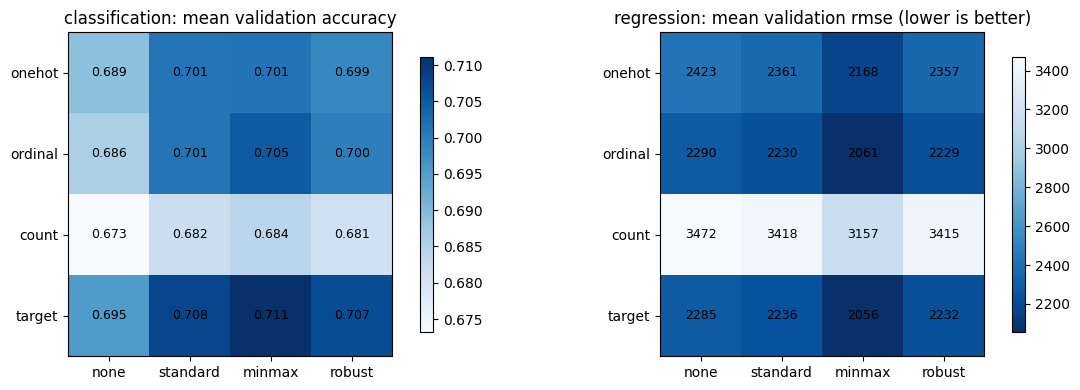

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task, cmap in zip(axes, ["classification", "regression"], ["Blues", "Blues_r"]):
    metric = config[task]["selection_metric"]
    pivot = grid_rankings[task].pivot(index="encoder", columns="scaler", values=f"mean_{metric}").loc[ENCODERS, SCALERS]
    image = ax.imshow(pivot.values, cmap=cmap)
    ax.set_xticks(range(len(SCALERS)), SCALERS)
    ax.set_yticks(range(len(ENCODERS)), ENCODERS)
    for i in range(len(ENCODERS)):
        for j in range(len(SCALERS)):
            ax.text(j, i, f"{pivot.values[i, j]:.3f}" if metric == "accuracy" else f"{pivot.values[i, j]:.0f}",
                    ha="center", va="center", fontsize=9)
    ax.set_title(f"{task}: mean validation {metric}" + (" (lower is better)" if metric == "rmse" else ""))
    fig.colorbar(image, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

**Is the winner really better, or is it the luck of the folds?** Same folds → subtract fold by fold. A mean advantage of more than 2 standard errors is a real edge. Within 2 SE, either pair is defensible, and the choice needs another reason.

In [11]:
pairs_to_check = {
    "classification": [(("target", "minmax"), ("target", "standard")), (("target", "standard"), ("target", "robust")),
                       (("target", "standard"), ("onehot", "robust"))],
    "regression": [(("ordinal", "minmax"), ("target", "minmax")), (("target", "minmax"), ("target", "robust"))],
}
rows = []
for task, pairs in pairs_to_check.items():
    higher_is_better = config[task]["selection_metric"] != "rmse"
    for a, b in pairs:
        result = paired_comparison(grid_scores[task][a], grid_scores[task][b], higher_is_better)
        rows.append({"task": task, "A": " + ".join(a), "B": " + ".join(b), **result})
paired_table = pd.DataFrame(rows)
display(paired_table.round(4))

,task,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,classification,target + minmax,target + standard,0.0033,0.0072,2,5,False
1,classification,target + standard,target + robust,0.0010,0.0012,3,5,False
2,classification,target + standard,onehot + robust,0.0093,0.0035,4,5,True
3,regression,ordinal + minmax,target + minmax,-5.8814,4.7305,1,5,False
4,regression,target + minmax,target + robust,176.5703,99.1993,5,5,False


**Decision** (stored in `config.yaml` → `classification.preprocessing` / `regression.preprocessing`). **Rule:** keep the current pair unless another pair is *decisively* better. Switching on noise would make the pipeline change every time the data changes.

- **Classification → target encoding + standard scaling.** `target + minmax` ranks first, but it is tied with `target + standard` (+0.003, SE 0.007), and so is `target + robust`. No pair is decisively better, so the current choice stays. Target encoding is also **decisively** ahead of one-hot (+0.009 vs `onehot + robust`, SE 0.0035, better on 4 of 5 folds) while using one column per feature instead of one per category. Count encoding takes the bottom 4 places: equal counts collide, and frequency says little about repurchase. Scaling matters: `target + none` drops to 0.695.
- **Regression → target encoding + min-max scaling.** It ranks first, and min-max is the best scaler for every encoder. With ridge, the scale decides how strongly each coefficient is penalised, so this is mostly a regularisation effect. `ordinal + minmax` is a tie (6 RMSE worse, SE 5), and ordinal encoding would impose an order on unordered categories (salesperson, transport method, …). `target + minmax` beats `target + robust` by ≈ 177 RMSE on all 5 folds (1.8 SE).

These pairs were chosen with the linear models. In section 3 the tree models use the same recipe; scaling doesn't change their splits.

# <font color='#2E86C1' size=6>**3. Recipe + model = one Pipeline**</font> <a class="anchor" id="pipeline"></a>

`build_pipeline()` (`src/pipeline.py`) puts `build_preprocessor()` and the model into one sklearn `Pipeline`. In every fold, `fit` learns the medians, the target-encoding means, the scaling statistics **and** the model from that fold's training rows only. `predict` then applies all of it unchanged to the validation block.

Candidates (`config.yaml` → `<task>.candidate_models`), each with its task's chosen recipe:

| | Classification | Regression |
|---|---|---|
| floor to beat | `DummyClassifier` (most frequent class) | `DummyRegressor` (mean) |
| linear | logistic regression | ridge |
| single tree | decision tree, depth 5 | decision tree, depth 5 |
| ensemble | random forest, 300 trees, ≥ 5 rows per leaf | random forest, 300 trees, ≥ 5 rows per leaf |

Hyperparameters are untouched defaults or simple limits for now; tuning comes later. **Train** vs **validation** scores show over- and under-fitting.

[Back to TOC](#toc)

In [12]:
model_results, model_fold_scores = {}, {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    recipe = task_preprocessing_config(config, task)
    metric = config[task]["selection_metric"]
    rows, model_fold_scores[task] = {}, {}
    for model_cfg in config[task]["candidate_models"]:
        pipe = build_pipeline(recipe, TASK_MODELS[task].build_model(model_cfg))
        scores = cross_validate_pipeline(pipe, X_dev, y_dev, task_folds[task], SCORING[task])
        rows[model_cfg["type"]] = scores.mean()
        model_fold_scores[task][model_cfg["type"]] = scores[f"validation_{metric}"].to_numpy()
    model_results[task] = pd.DataFrame(rows).T
    print(f"\n{task} ({recipe['encoder']} + {recipe['scaler']}): mean over {len(task_folds[task])} temporal folds")
    display(model_results[task].round(4))


classification (target + standard): mean over 5 temporal folds


,train_accuracy,validation_accuracy,train_f1,validation_f1,train_roc_auc,validation_roc_auc
dummy,0.5532,0.5530,0.7122,0.7117,0.5000,0.5000
logistic_regression,0.7081,0.7078,0.7232,0.7237,0.7757,0.7728
decision_tree,0.7378,0.6515,0.7589,0.6836,0.8034,0.6972
random_forest,0.8504,0.7083,0.8623,0.7429,0.9380,0.7790



regression (target + minmax): mean over 5 temporal folds


,train_rmse,validation_rmse,train_mae,validation_mae,train_r2,validation_r2
dummy,1940.1767,2471.5528,1358.6014,1637.9819,0.0000,-0.0496
ridge,1485.4665,2055.5762,997.4644,1397.0025,0.4141,0.2273
decision_tree,1200.7443,2370.9578,813.1190,1467.9438,0.6189,-0.0194
random_forest,985.1740,1942.4794,588.7954,1275.0570,0.7309,0.3312


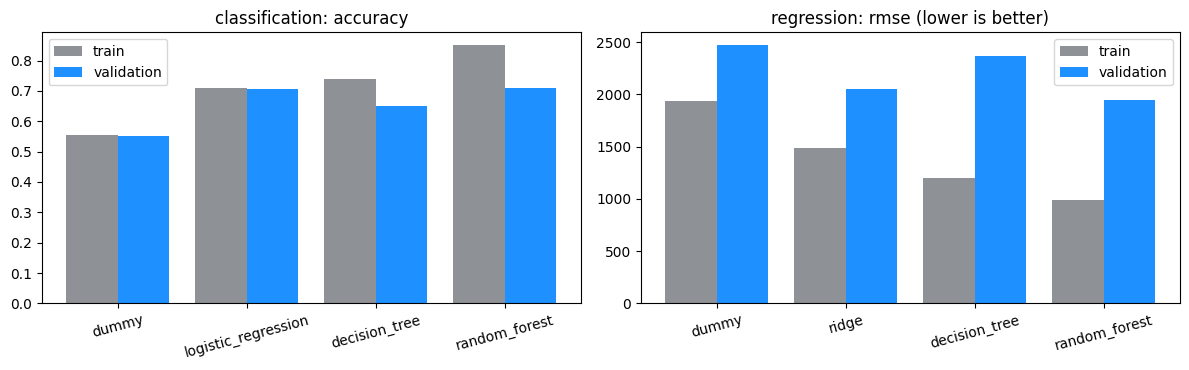

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, task in zip(axes, ["classification", "regression"]):
    metric = config[task]["selection_metric"]
    table = model_results[task][[f"train_{metric}", f"validation_{metric}"]]
    positions = np.arange(len(table))
    ax.bar(positions - 0.2, table[f"train_{metric}"], width=0.4, color="#8E9196", label="train")
    ax.bar(positions + 0.2, table[f"validation_{metric}"], width=0.4, color="dodgerblue", label="validation")
    ax.set_xticks(positions, table.index, rotation=15)
    ax.set_title(f"{task}: {metric}" + (" (lower is better)" if metric == "rmse" else ""))
    ax.legend()
plt.tight_layout()
plt.show()

In [14]:
rows = []
for task, comparisons in {
    "classification": [("logistic_regression", "dummy"), ("logistic_regression", "random_forest")],
    "regression": [("random_forest", "dummy"), ("random_forest", "ridge")],
}.items():
    higher_is_better = config[task]["selection_metric"] != "rmse"
    for a, b in comparisons:
        result = paired_comparison(model_fold_scores[task][a], model_fold_scores[task][b], higher_is_better)
        rows.append({"task": task, "A": a, "B": b, **result})
display(pd.DataFrame(rows).round(4))

,task,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,classification,logistic_regression,dummy,0.1548,0.0187,5,5,True
1,classification,logistic_regression,random_forest,-0.0005,0.0035,3,5,False
2,regression,random_forest,dummy,529.0734,113.9682,5,5,True
3,regression,random_forest,ridge,113.0968,73.7393,3,5,False


**Regression target transform.** `spend_next_90d` is strongly right-skewed (median ≈ 1,000 €, a long tail up to ≈ 25,000 €). A common fix is to fit on `log1p(spend)` and transform predictions back (`regression.model.target_transform: log1p`, a `TransformedTargetRegressor`). Is it better here, measured in euros on the same folds?

In [15]:
print(f"skew of spend_next_90d: {splits['regression'][2].skew():.2f}  |  skew of log1p(spend): {np.log1p(splits['regression'][2]).skew():.2f}")

X_dev, _, y_dev, _, _, _ = splits["regression"]
recipe = task_preprocessing_config(config, "regression")
transform_scores, rows = {}, []
for model_cfg in config["regression"]["candidate_models"]:
    if model_cfg["type"] == "dummy":
        continue
    for transform in ["none", "log1p"]:
        model = regression_model.build_model({**model_cfg, "target_transform": transform})
        scores = cross_validate_pipeline(build_pipeline(recipe, model), X_dev, y_dev, task_folds["regression"], SCORING["regression"])
        transform_scores[(model_cfg["type"], transform)] = scores["validation_rmse"].to_numpy()
        rows.append({"model": model_cfg["type"], "target_transform": transform,
                     **scores[["validation_rmse", "validation_mae", "validation_r2"]].mean().to_dict()})
display(pd.DataFrame(rows).round(3))

display(pd.DataFrame([
    {"model": name, "A": "log1p", "B": "none",
     **paired_comparison(transform_scores[(name, "log1p")], transform_scores[(name, "none")], higher_is_better=False)}
    for name in ["ridge", "decision_tree", "random_forest"]
]).round(3))

skew of spend_next_90d: 2.40  |  skew of log1p(spend): -0.59


,model,target_transform,validation_rmse,validation_mae,validation_r2
0,ridge,none,2055.576,1397.002,0.227
1,ridge,log1p,2788.210,1508.874,-0.381
2,decision_tree,none,2370.958,1467.944,-0.019
3,decision_tree,log1p,2474.543,1458.189,-0.087
4,random_forest,none,1942.479,1275.057,0.331
5,random_forest,log1p,2327.040,1348.401,0.045


,model,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,ridge,log1p,none,-732.634,325.402,0,5,True
1,decision_tree,log1p,none,-103.585,106.780,2,5,False
2,random_forest,log1p,none,-384.560,62.179,0,5,True


**Verdict: no transform** (`target_transform: none`). The log scale removes the skew, but in RMSE it is decisively worse for ridge (+733) and for the chosen random forest (+385, worse on all 5 folds). For the depth-5 tree, the weakest model, it is also worse, but not decisively (+104 ± 107 RMSE). A model fitted on `log1p(spend)` predicts something close to the *median* spend once transformed back, so it underestimates the large spenders that dominate RMSE. The option stays available in `regression/model.py` for a log-scale metric (e.g. RMSLE).

**Decision** (stored in `config.yaml` → `<task>.model`), with the same rule as section 2:

- **Classification → logistic regression.** It beats the dummy on every fold (0.708 vs 0.553), and train ≈ validation (0.708 / 0.708), so it doesn't overfit. The random forest ties it (0.0005 ahead, SE 0.0035, better on 2 of 5 folds), with slightly better F1/ROC-AUC, but it overfits (train 0.85) and isn't decisively better, so logistic regression stays: simpler, stable, and easy to explain. The single depth-5 tree is clearly worse (0.652).
- **Regression → random forest.** It has the lowest validation RMSE (≈ 1942 vs 2056 for ridge and 2472 for the dummy) and the highest R² (≈ 0.33). Its edge over ridge holds on 3 of 5 folds and is not decisive (≈ 113 RMSE, SE 74). It also overfits clearly (train RMSE ≈ 985), which tuning should address. The single depth-5 tree is barely better than the dummy (R² −0.02 vs −0.05): one tree overfits the extra customer categories. The target is kept in euros (no log transform, see above).

Every chosen model beats its dummy floor on every fold, so the preprocessing produces usable signal for both tasks. These are **development-set** scores. The locked test set is still untouched and is scored once, at the end, for the final models.

In [16]:
final_pipelines = {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    final_pipelines[task] = build_pipeline(
        task_preprocessing_config(config, task), TASK_MODELS[task].build_model(config[task]["model"]),
    ).fit(X_dev, y_dev)                                  # all development rows; locked test still untouched
final_pipelines["classification"]

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


**Conclusion:** Preprocessing and model are a single estimator per task, fitted on the development rows only. Both chosen models clearly beat their dummy baselines. The locked test set is still untouched.

# <font color='#2E86C1' size=6>**4. Model scores with the final recipe**</font> <a class="anchor" id="scores"></a>

The candidate models of each task (`<task>.candidate_models`), scored with the final preprocessing. In the README, these numbers replace those of section 3.

[Back to TOC](#toc)

In [17]:
model_rows = []
for task in ["classification", "regression"]:
    d = prepare_task_data(config, task)
    folds = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])
    metric = config[task]["selection_metric"]
    for model_cfg in config[task]["candidate_models"]:
        s = cross_validate_pipeline(build_pipeline(d["preprocessing_config"], TASKS[task].model.build_model(model_cfg)),
                                    d["X_dev"], d["y_dev"], folds, SCORING[task])
        model_rows.append({"task": task, "model": model_cfg["type"], f"train": s[f"train_{metric}"].mean(),
                           "validation": s[f"validation_{metric}"].mean(), "validation std": s[f"validation_{metric}"].std(ddof=1)})
display(pd.DataFrame(model_rows).round(4))

,task,model,train,validation,validation std
0,classification,dummy,0.5532,0.5530,0.0345
1,classification,logistic_regression,0.7081,0.7078,0.0155
2,classification,decision_tree,0.7378,0.6515,0.0397
3,classification,random_forest,0.8504,0.7083,0.0114
4,regression,dummy,1940.1767,2471.5528,237.7549
5,regression,ridge,1485.4665,2055.5762,289.3056
6,regression,decision_tree,1200.7443,2370.9578,378.9080
7,regression,random_forest,985.1740,1942.4794,165.1851


In the README, these replace the numbers of section 3.

- **Classification:** logistic regression (0.7078, train 0.7081) stays the chosen model. The random forest is 0.0005 ahead (0.7083, SE 0.0035, better on 2 of 5 folds: a tie), and it overfits (0.85 on training).
- **Regression:** the random forest (1,942, R² 0.33) stays the chosen model, 113 RMSE ahead of ridge (2,056) and 529 below the dummy (2,472).
- **The depth-5 decision tree** moves the most between versions (0.65 / 2,371), as small trees do.

# <font color='#2E86C1' size=6>**5. From this notebook to the pipeline**</font> <a class="anchor" id="to-pipeline"></a>

| This notebook | Pipeline |
|---|---|
| Section 1 | `src/preprocessing.py` → `check_feature_lists()`, `build_preprocessor()` (with the `MissingIndicator` step); `src/pipeline.py` → `build_pipeline()`, `save_pipeline()`, `load_pipeline()`, `predict_new_records()`; `tests/test_pipeline.py` |
| Section 2 | `src/evaluate.py` → `temporal_folds()`, `compare_encoders_scalers()`, `paired_comparison()`; `config.yaml` → `cv`, `<task>.comparison_model`, `<task>.preprocessing` |
| Sections 3–4 | `src/evaluate.py` → `cross_validate_pipeline()`; `<task>/model.py` → `build_model()` (regression: `target_transform`); `<task>/evaluate.py` → `SCORING`, reports; `config.yaml` → `<task>.metrics`, `<task>.selection_metric`, `<task>.candidate_models`, `<task>.model` |
| Everything (notebooks 01–06) | `python main.py`: validation, cleaning, temporal CV against the dummy floor, optional Optuna tuning with nested CV (`src/tuning.py`, `<task>.tuning`), refit, scoreboard and report (`src/results.py`, `results/`), saved model (`models/`) and test.csv predictions (`results/predictions/`) |

[Back to TOC](#toc)